In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
path = r"C:\Cotemig\Python\Atividade_pag.67e68\vendas.csv"

In [15]:
vendas = pd.read_csv(path, header=0, sep=',', encoding='utf-8')

In [20]:
vendas.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   data            50 non-null     datetime64[us]
 1   loja            50 non-null     str           
 2   produto         50 non-null     str           
 3   quantidade      49 non-null     float64       
 4   preco_unitario  49 non-null     float64       
 5   regiao          50 non-null     str           
 6   categoria       50 non-null     str           
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 2.9 KB


In [19]:
vendas["data"] = pd.to_datetime(vendas["data"])

In [22]:
vendas["faturamento"] = vendas["quantidade"] * vendas["preco_unitario"]

In [29]:
vendas.info()
vendas.isnull().sum()
vendas.describe()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   data            50 non-null     datetime64[us]
 1   loja            50 non-null     str           
 2   produto         50 non-null     str           
 3   quantidade      49 non-null     float64       
 4   preco_unitario  49 non-null     float64       
 5   regiao          50 non-null     str           
 6   categoria       50 non-null     str           
 7   faturamento     48 non-null     float64       
dtypes: datetime64[us](1), float64(3), str(4)
memory usage: 3.3 KB


,data,quantidade,preco_unitario,faturamento
count,50,49.000000,49.000000,48.000000
mean,2025-05-31 14:52:48,4.346939,134.185714,464.460417
min,2025-01-05 00:00:00,1.000000,39.900000,179.600000
25%,2025-03-15 12:00:00,3.000000,59.900000,294.375000
50%,2025-06-02 12:00:00,4.000000,124.900000,426.900000
75%,2025-08-12 12:00:00,5.000000,169.900000,559.350000
max,2025-10-30 00:00:00,11.000000,279.900000,1399.500000
std,NaN,2.394012,82.291403,242.643459


In [32]:
vendas["quantidade"].fillna(vendas["quantidade"].mean())
vendas["preco_unitario"].fillna(vendas["preco_unitario"].mean())

0      59.900000
1     119.900000
2     249.900000
3     249.900000
4      39.900000
5      59.900000
6     119.900000
7     149.900000
8     249.900000
9      39.900000
10     59.900000
11    119.900000
12    149.900000
13    249.900000
14     39.900000
15     59.900000
16    119.900000
17    249.900000
18    149.900000
19     39.900000
20     64.900000
21    124.900000
22    269.900000
23     44.900000
24    159.900000
25     64.900000
26    124.900000
27    269.900000
28     44.900000
29    159.900000
30     69.900000
31    129.900000
32    279.900000
33    169.900000
34     49.900000
35     69.900000
36    134.185714
37    279.900000
38     49.900000
39    169.900000
40     69.900000
41    129.900000
42    279.900000
43     49.900000
44    169.900000
45     69.900000
46    129.900000
47    279.900000
48    169.900000
49     49.900000
Name: preco_unitario, dtype: float64

In [36]:
vendas["faturamento"].groupby(vendas["data"].sort_values()).sum()

data
2025-01-05     179.7
2025-01-08     239.8
2025-01-12     249.9
2025-01-18     499.8
2025-01-25     199.5
2025-02-03     239.6
2025-02-07     359.7
2025-02-11     299.8
2025-02-19     749.7
2025-02-26     239.4
2025-03-04     299.5
2025-03-09     239.8
2025-03-14     599.6
2025-03-20     499.8
2025-03-28     279.3
2025-04-02     359.4
2025-04-08     479.6
2025-04-15     499.8
2025-04-21     449.7
2025-04-29     319.2
2025-05-05     194.7
2025-05-10     624.5
2025-05-16     269.9
2025-05-23     179.6
2025-05-30     479.7
2025-06-06     454.3
2025-06-12     374.7
2025-06-18     539.8
2025-06-24     404.1
2025-06-29     319.8
2025-07-04     349.5
2025-07-09     259.8
2025-07-15    1119.6
2025-07-21     849.5
2025-07-28     499.0
2025-08-03       0.0
2025-08-08       0.0
2025-08-14     559.8
2025-08-20     299.4
2025-08-27     679.6
2025-09-05     559.2
2025-09-11     649.5
2025-09-17     839.7
2025-09-23     349.3
2025-09-29     509.7
2025-10-06     629.1
2025-10-12     389.7
2025-10-

In [37]:
vendas["ticket"] = vendas["faturamento"] / vendas["quantidade"]

In [48]:
produtos_mais_vendidos = vendas.groupby("produto")["quantidade"].sum().sort_values().head(5)

In [51]:
faturamento_mensal = vendas.groupby(vendas["data"])["faturamento"].sum()

mes_maior = faturamento_mensal.idxmax()
mes_menor = faturamento_mensal.idxmin()

In [57]:
print(mes_maior)
print(mes_menor)

2025-10-18 00:00:00
2025-08-03 00:00:00


In [58]:
vendas["mes"] = vendas["data"].dt.month

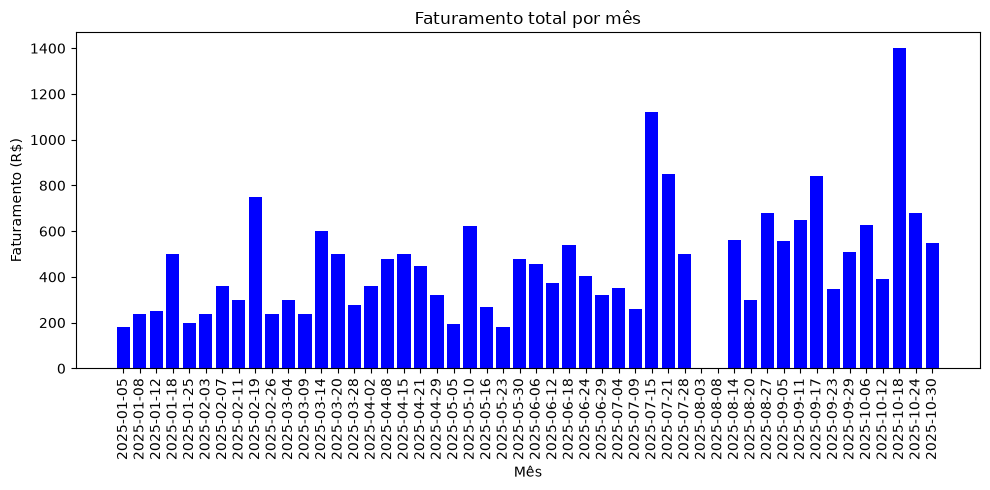

In [71]:
plt.figure(figsize=(10, 5))
plt.bar(faturamento_mensal.index.astype(str), faturamento_mensal.values, color="blue")

plt.title("Faturamento total por mês")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

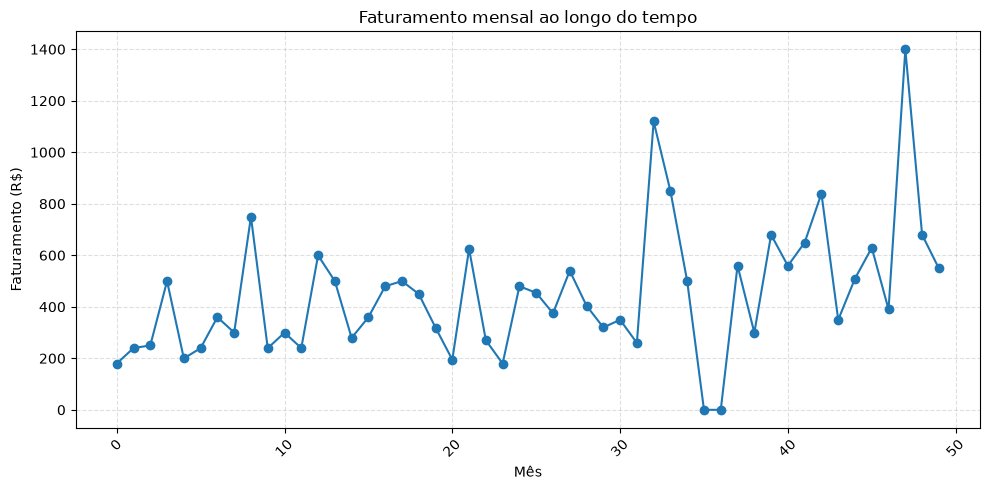

In [76]:
plt.figure(figsize=(10, 5))
plt.plot(faturamento_mensal.values, marker="o")

plt.title("Faturamento mensal ao longo do tempo")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

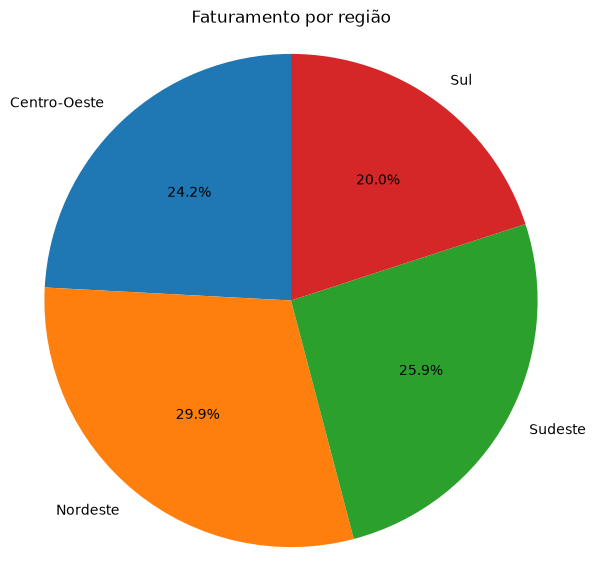

In [77]:
faturamento_regiao = vendas.groupby("regiao")["faturamento"].sum()

plt.figure(figsize=(7, 7))
plt.pie(
    faturamento_regiao,
    labels=faturamento_regiao.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Faturamento por região")
plt.axis("equal")
plt.show()

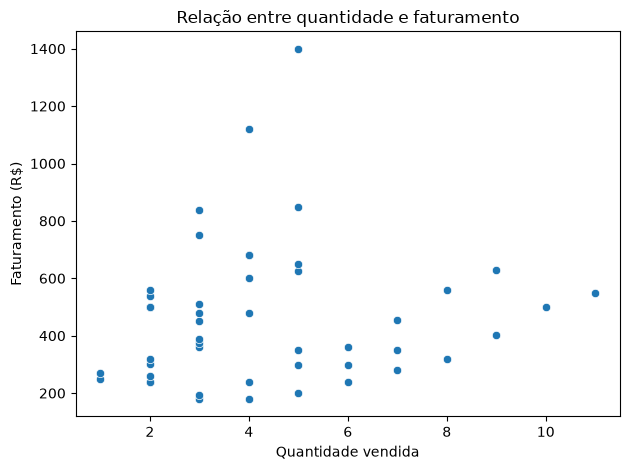

In [83]:
sns.scatterplot(data=vendas, x="quantidade", y="faturamento")
plt.title("Relação entre quantidade e faturamento")
plt.xlabel("Quantidade vendida")
plt.ylabel("Faturamento (R$)")
plt.tight_layout()
plt.show()

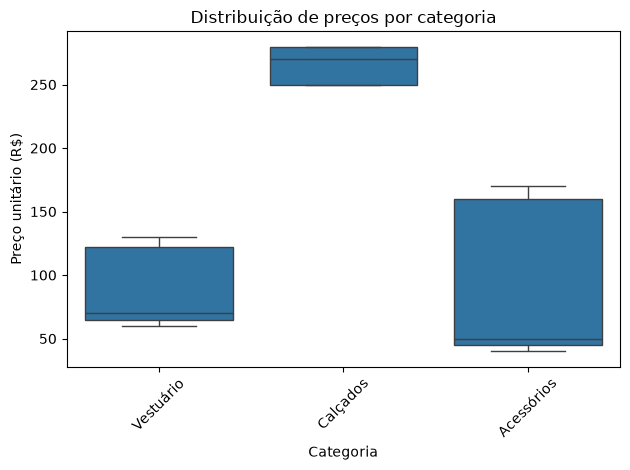

In [81]:
sns.boxplot(data=vendas, x="categoria", y="preco_unitario")

plt.title("Distribuição de preços por categoria")
plt.xlabel("Categoria")
plt.ylabel("Preço unitário (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

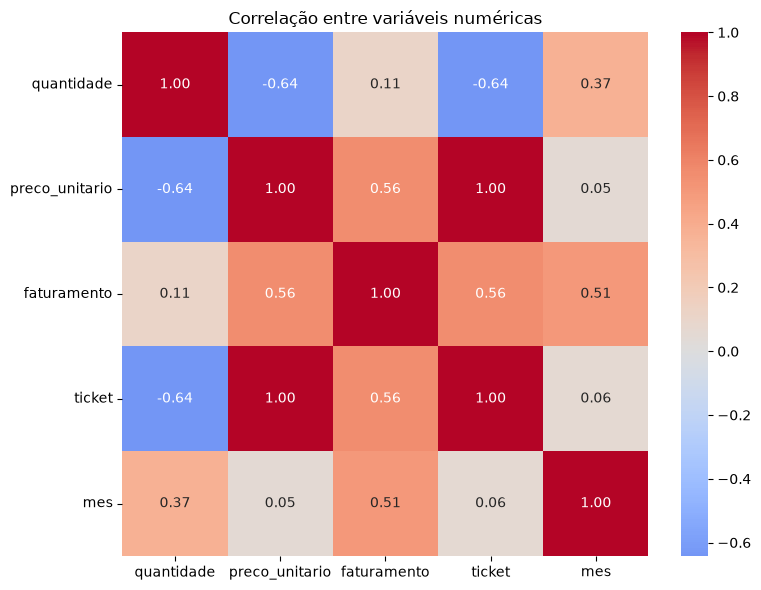

In [84]:
correlacao = vendas.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

In [85]:
sns.set_style("whitegrid")
sns.set_palette("deep")

In [89]:
faturamento_mensal = (
    vendas.groupby(vendas["data"])["faturamento"]
    .sum()
    .reset_index()
)

faturamento_regiao = (
    vendas.groupby("regiao")["faturamento"]
    .sum()
    .reset_index())

faturamento_mensal.to_csv("faturamento_mensal.csv", index=False, encoding="utf-8-sig")
faturamento_regiao.to_csv("faturamento_regiao.csv", index=False, encoding="utf-8-sig")